# Stopping model: time-varying bound, sensory noise, guesses, and lapses

**Status (2026-10-10, model version 3):** `src/pigeon/stopping.py` (tests in
`tests/test_stopping.py`). Focus: OL (blocks 1–6) and MX (blocks 1–3). The bound
plateau and its variability and the guess, lapse and anticipation rates are per
block; the bound's time course (knee form: an early segment falling to a
plateau at a free knee step, then a slow late slope), sensory noise and NDT are
shared across a subject's blocks. The **bound plateau** (`bound_scale`, the
mean bound at the knee) is the paper's single bound measure (Figures 4 and 5). Anticipations are first-frame presses (RT = 1) only. Trials follow the paper's conventions. Fits
and recovery are run by scripts and cached in `data/processed/`. MXSC and the
change-point blocks come after OL and MX are settled.

## Why this notebook

Every bound analysis in the paper treats each trial as a bound crossing and handles
guessing only by filtering (`DT >= 2`, `trial_number >= 10`, the `rt_below_cutoff`
from `get_bounds`). This notebook fits an explicit trial-level model of *when*
subjects stop and *which* side they choose, so that guesses are estimated rather
than filtered.

**Why not accuracy or congruence.** With Gaussian steps of mean ±μ, the
likelihood ratio for "right" vs. "left" depends only on the current position `x`.
So for a subject who chooses the side the pigeon is on, P(correct | x at commit)
= logistic(2μ|x|/σ²), *whatever* rule decided when to stop. Accuracy (and
congruence) therefore cannot separate a low bound from evidence-independent
stopping; only the timing of commitments can. A bound-based rule and a
random-timing rule both give accuracy that rises with SNR and with commit time
(see `scratchpad/acc_policy.py` from the 2026-10-09 session).

## Task facts the model relies on

- Steps are Gaussian: `move_pigeon_function` in both `task/OL-MX-PD/PigeonTask.js`
  and `task/MXSC/PigeonTask.js` draws `step_mean + step_std * N(0, 1)` (Marsaglia
  polar method).
- `steps` records the *displayed* position, clamped at ±0.75 (`EDGE_DISTANCE`);
  the walk itself is not clamped. Once at the wall the pigeon stays at the edge
  until the key press, so a long RT after a wall hit says nothing about stopping.
  Wall hits are common in OL/MX (11–14% of trials) and rare in MXSC (49 trials).
- A response is possible on the trial's first frame, before any step (RT = 1):
  14% of OL trials, 11% of MX, 2% of MXSC. These are commits with no evidence
  (anticipations).
- Each position is shown for 200 ms (`UPDATE_INTERVAL = 0.2` in both task
  versions), so an NDT of n steps means the key press came 200·n to 200·(n+1) ms
  after the commit position appeared.
- **Datasets:** OL, MX and MXSC. Not PD: there the bound is set before the trial,
  so there is no voluntary stopping to model.

## Model (version 3)

Notation: `x_j` is the on-screen position after `j` steps (`x_0 = 0`).

1. **Anticipation.** With probability `a` the key is pressed during the trial's
   first frame (RT = 1), before anything shown could be processed; choice random.
   (Until 2026-10-10 anticipations were spread over the first NDT + 1 frames,
   which over-predicted RT = 1 and under-predicted RT = 2.)
2. **Bound.** The bound at step `j` is `b_j = m · θ(j)`. The trial's multiplier `m`
   is gamma-distributed with mean 1 and coefficient of variation `bound_cv`
   (trial-to-trial bound variability). The time course is
   `θ(j) = bound_scale · h(j)`. **Knee form** (default since 2026-10-10): `log h`
   falls (or rises) linearly from `log_h_start` at step 1 to 0 at a free,
   continuous knee step (1.5–15), then changes by `late_slope` per step. So
   `bound_scale` is the mean bound at the knee: the **bound plateau**. Penalty:
   prior SD 0.5 on `log_h_start` and on the change over 10 late steps; the knee
   is unpenalized. The previous form (`time_course_form='knots'`: `log h`
   piecewise linear through knots at steps 1, 6 and 16, `h(6) = 1`) fit worse by
   AIC (see the model comparison) and put its second knot too late: most of the
   collapse happens in the first ~3 steps.
3. **Sensory noise.** The subject sees `y_j = x_j + e_j`, with independent
   `e_j ~ N(0, sensory_std²)`, and commits at the first `j ≥ 1` with `|y_j| ≥ b_j`,
   choosing the side crossed. This lets commits happen away from the pigeon's
   visible maximum and makes choices near the center noisy (the incongruence that
   Figure03S03 attributes to sensory noise).
4. **Guess.** If the bound isn't crossed at step `j`, the subject commits anyway
   with probability `g`, choosing the side of the perceived position. This
   includes step 0 (pigeon at center: random choice, RT = NDT + 1).
5. **Lapse.** With probability `ε` the choice is random (the incongruence floor at
   large bounds in Figure03S03, which noise can't produce).
6. **NDT** ∈ {1, 2} steps (200–600 ms from the commit position to the key press),
   probabilities fit per subject and shared across blocks. Longer delays aren't
   plausible as a sensorimotor latency; allowing them lets the model push commits
   back to the first step of short trials and infer implausibly low bounds.
   NDT 1–3 is kept only as a sensitivity check.

**Change-point blocks:** separate `bound_scale` (optionally `g`) for positions from
the change-point step on. Because the bound's time course is modeled, a bound that
falls over the trial is not mistaken for a post-change-point shift.

**Likelihood.** Given `m`, steps are independent, so each trial's likelihood is a
product over steps, integrated over `m` and averaged over NDT. The integral uses
Gauss–Legendre quadrature only over the window of `m` where that trial's
likelihood changes (below it the bound would have been crossed earlier; above it
only guesses can commit, in closed form). Exact without noise; within ~0.15
log-likelihood units of a 128-node reference otherwise.

**Wall-hit trials** answered later than any NDT allows (RT > wall step + 3) are
censored at the wall; all other trials use the ordinary likelihood.

**Trial selection** (`get_stopping_model_trials`): raw block numbering
(`combine_snr=False`; OL blocks 1–6, each a single SNR; MX blocks 1–3, mixed
SNR, the ones `combine_snr=True` keeps). A trial is dropped if
`trial_number < 10` or, for a subject with a good adaptation fit in that block
(`get_adaptation_tau_fits`, as in Figure04), `trial_number < ceil(τ)`; so the
effective cutoff is `max(10, ceil(τ))`. Trials without a choice (step budget ran
out) are dropped. No DT cutoff, no wall-hit exclusion, no bias correction.

**Which parameters are per block** (chosen by model comparison; see below).
`bound_scale`, `bound_cv`, `g`, `ε` and `a` are separate per block; the time
course (3 knee parameters), `sensory_std` and P(NDT = 1) are shared across a
subject's blocks. Free parameters per subject: 5 per block + 5 (OL: 35; MX: 20).

### Version 1 and why it was revised

Version 1 had a constant bound, no sensory noise and NDT 1–3. It fit the fixed
blocks well but only by attributing 20–67% of commits to "guesses", because any
commit not at the pigeon's farthest point so far had to be a guess. Figure03S03's
analysis (incongruence needs sensory noise; premature crossings need either NDT
> 2 or, as noted here, a bound that falls over the trial) and the implausibility
of NDT ≥ 3 at 200 ms per step led to version 2.

## Plan

1. **Implementation** (done): likelihood, simulator, fitter in `pigeon.stopping`, with tests.
2. **Recovery and mechanism attribution:** simulate at each dataset's trial counts;
   check parameter recovery, and that data generated by only guesses, only sensory
   noise, or only a collapsing bound are attributed to the right mechanism.
3. **Fixed blocks (OL, MX, MXSC Low/High):** fit; check against RT distributions,
   accuracy, and Figure03S03's incongruence and premature-crossing curves; compare
   variants (time course flat/shared/per block; NDT 1–2 vs 1–3; noise on/off) by
   held-out likelihood.
4. **How much guessing remains**, and how much survives the `DT >= 2` filter.
5. **Change-point blocks:** post − pre `bound_scale` within LowHigh and HighLow,
   with the time course accounted for, against simulated nulls.
6. **Decision:** whether guessing, noise or the bound's time course must be built
   into the bias correction, RR matrices and null models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from pigeon.data import get_crossing_diagnostics, get_good_trial_array
from pigeon.stopping import (KNEE_PARAMS, bound_time_course, get_log_h, get_stopping_model_trials,
                             infer_bounds_like_data, simulate_stopping_data_table)

PROCESSED = Path('../data/processed')

## Parameter recovery at OL and MX trial counts

From `scripts/run_stopping_recovery.py` (cached in `data/processed/stopping_recovery.pkl`).
Simulated subjects with each block's median real trial count after the exclusions
(OL: 111, 64, 33, 150, 121, 78; MX: 114, 92, 47) and step statistics (step SD
0.15; mean 0.05 or 0.15, mixed 50/50 within MX blocks), fit with the defaults.
True bound scale and CV and the guess, lapse and anticipation rates are drawn
per block; sensory noise, NDT and the time course (random log-linear) per subject.

converged: {'MX': 1.0, 'OL': 1.0}


parameter        anticipation_rate  bound_cv  bound_scale  guess_rate  knee  \
task block                                                                    
MX   B1 (n=114)               0.83      0.70         0.95        0.77   NaN   
     B2 (n=92)                0.55      0.66         0.96        0.69   NaN   
     B3 (n=47)                0.61      0.58         0.89        0.66   NaN   
     shared                    NaN       NaN          NaN         NaN  0.66   
OL   B1 (n=111)               0.87      0.81         0.99        0.84   NaN   
     B2 (n=64)                0.75      0.53         0.98        0.77   NaN   
     B3 (n=33)                0.49      0.52         0.95        0.59   NaN   
     B4 (n=150)               0.89      0.88         0.97        0.88   NaN   
     B5 (n=121)               0.87      0.83         0.98        0.66   NaN   
     B6 (n=78)                0.91      0.75         0.97        0.67   NaN   
     shared                    NaN       NaN          NaN         NaN  0.62   

parameter        lapse_rate  late_slope  log_h_start  ndt_p1  sensory_std  
task block                                                                 
MX   B1 (n=114)        0.65         NaN          NaN     NaN          NaN  
     B2 (n=92)         0.40         NaN          NaN     NaN          NaN  
     B3 (n=47)         0.51         NaN          NaN     NaN          NaN  
     shared             NaN        0.86         0.88    0.96         0.30  
OL   B1 (n=111)        0.68         NaN          NaN     NaN          NaN  
     B2 (n=64)         0.52         NaN          NaN     NaN          NaN  
     B3 (n=33)         0.14         NaN          NaN     NaN          NaN  
     B4 (n=150)        0.66         NaN          NaN     NaN          NaN  
     B5 (n=121)        0.55         NaN          NaN     NaN          NaN  
     B6 (n=78)         0.66         NaN          NaN     NaN          NaN  
     shared             NaN        0.85         0.94    0.97         0.89

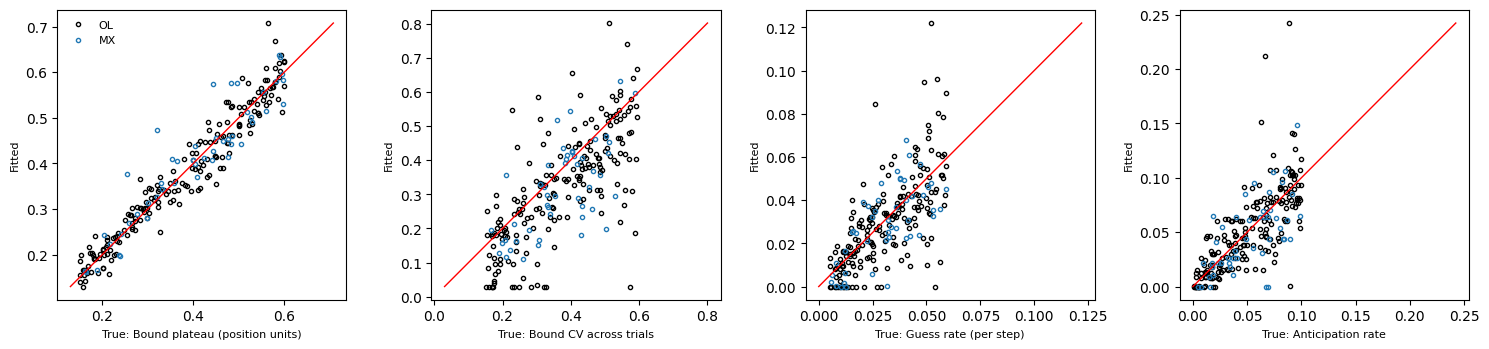

In [2]:
recovery = pd.read_pickle(PROCESSED / 'stopping_recovery.pkl')
print('converged:', recovery.groupby(['task', 'seed']).converged.first().groupby('task').mean().to_dict())

rows = []
for task, g in recovery.groupby('task'):
    s = g.groupby('seed').first()
    for k in ('sensory_std', 'ndt_p1', 'log_h_start', 'knee', 'late_slope'):
        rows.append({'task': task, 'block': 'shared', 'parameter': k, 'r': np.corrcoef(s[f'true_{k}'], s[f'fit_{k}'])[0, 1],
                     'median |error|': np.median(np.abs(s[f'fit_{k}'] - s[f'true_{k}']))})
    for b, gb in g.groupby('block'):
        for k in ('bound_scale', 'bound_cv', 'guess_rate', 'lapse_rate', 'anticipation_rate'):
            rows.append({'task': task, 'block': f'B{b} (n={gb.n_trials.median():.0f})', 'parameter': k,
                         'r': np.corrcoef(gb[f'true_{k}'], gb[f'fit_{k}'])[0, 1],
                         'median |error|': np.median(np.abs(gb[f'fit_{k}'] - gb[f'true_{k}']))})
rec_table = pd.DataFrame(rows)
display(rec_table.pivot_table(index=['task', 'block'], columns='parameter', values='r').round(2))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (k, label) in zip(axes, [('bound_scale', 'Bound plateau (position units)'), ('bound_cv', 'Bound CV across trials'),
                                 ('guess_rate', 'Guess rate (per step)'), ('anticipation_rate', 'Anticipation rate')]):
    for task, color in (('OL', 'k'), ('MX', 'tab:blue')):
        g = recovery[recovery.task == task]
        ax.plot(g[f'true_{k}'], g[f'fit_{k}'], 'o', mfc='none', color=color, ms=3, label=task)
    lims = [recovery[[f'true_{k}', f'fit_{k}']].min().min(), recovery[[f'true_{k}', f'fit_{k}']].max().max()]
    ax.plot(lims, lims, 'r-', lw=1)
    ax.set_xlabel(f'True: {label}', fontsize=8)
    ax.set_ylabel('Fitted', fontsize=8)
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

**Recovery (2026-10-11, knee-form defaults).** All 48 fits converged. Each
block's **bound plateau** recovers very well (r = 0.89–0.99, including the
33-trial OL block); bound CV moderately (0.52–0.88). Of the shared parameters,
NDT (0.96–0.97), the start height `log_h_start` (0.88–0.94) and the late slope
(0.85–0.86) recover well, the knee step moderately (0.62–0.66), and sensory
noise well in OL (0.89) but poorly in MX (0.30). Guess rates recover
moderately (0.59–0.88) and lapse rates poorly to moderately (0.14–0.68);
anticipation rates moderately to well (0.49–0.91). So interpret guess and
lapse rates at the group level, not per subject and block. (The knots-form
recovery of 2026-10-10 is archived in `data/processed/stopping_fits_round3_knots/`.)

An earlier recovery run (MXSC counts, time course shared) checked mechanism
attribution: data generated by only guesses, only sensory noise, or only a
collapsing bound were each attributed to the right mechanism (guess-only data gave
a small spurious collapse, about −0.06 in log h at step 6).

## Fits to OL and MX

Fits come from `scripts/run_stopping_fits.py` (cached in
`data/processed/stopping_fits_<variant>.pkl`). Main variant: bound plateau and CV,
guess, lapse and anticipation rates per block; the knee-form time course, sensory
noise and NDT {1, 2} shared across a subject's blocks. Variants for comparison
(all knee form unless noted): `knots` (the previous time-course form),
`knee_flat` (bound flat after the knee), `tc_by_snr` (one time course per SNR),
`per_block_tc` (time course per block), `flat` (no time course),
`flat_guess_tc` (constant bound, guess rate varying over the trial, knots form),
`both_tc` (both time courses, knots form), `shared_rates` (guess, lapse and
anticipation shared across blocks), `ndt123` (NDT 1–3), `no_noise` (sensory
noise fixed at 0). Fits of earlier model versions are archived in
`data/processed/stopping_fits_round1/`, `_round2/` and `_round3_knots/`.

**Why this split (round 1, 2026-10-09).** A first round with bound parameters
(including the time course) per block and the three rates shared found, by AIC
summed over subjects: rates per block much better (ΔAIC −12,039 OL, −1,007 MX;
e.g. 33% of OL block-4 responses at RT = 1 vs. a much lower rate in blocks 2–3);
one time-course shape per subject better than per-block shapes (−846 OL, −398 MX);
a constant bound worse (+2,382, +903); no sensory noise worse (+1,975, +453); NDT
1–3 worse than 1–2 (+203, +252). Round-1 fits are archived in
`data/processed/stopping_fits_round1/`.

In [3]:
DATASETS = {'OL': [1, 2, 3, 4, 5, 6], 'MX': [1, 2, 3]}
tables = {task: get_stopping_model_trials(task, blocks) for task, blocks in DATASETS.items()}
VARIANT_NAMES = ['main', 'knots', 'knee_flat', 'tc_by_snr', 'per_block_tc', 'flat', 'flat_guess_tc',
                 'both_tc', 'shared_rates', 'ndt123', 'no_noise']
fits_all = {v: pd.read_pickle(PROCESSED / f'stopping_fits_{v}.pkl')
            for v in VARIANT_NAMES if (PROCESSED / f'stopping_fits_{v}.pkl').exists()}
fits = fits_all['main']
by_subj = fits.groupby(['task', 'subject_index']).first()
print('variants available:', list(fits_all))
print('main: fits that did not converge, by task:', (~by_subj.success).groupby('task').sum().to_dict(),
      '| fits that raised:', int(by_subj.error.notna().sum()))

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


MX: subjects with a good adaptation tau fit, by block: {1: 3, 2: 15, 3: 11}
MX: 18,726 trials in blocks [1, 2, 3]; excluded 1,620 with trial_number < 10, 58 more in the adaptation transient, 182 more with no choice; 60 subjects
variants available: ['main', 'knots', 'knee_flat', 'tc_by_snr', 'per_block_tc', 'flat', 'flat_guess_tc', 'both_tc', 'shared_rates', 'ndt123', 'no_noise']
main: fits that did not converge, by task: {'MX': 1, 'OL': 0} | fits that raised: 0


### Parameter estimates (main variant)

Median [interquartile range] across subjects. Per-block parameters: bound
level and CV and the guess, lapse and anticipation rates (`bound_scale` = the bound plateau, the mean bound at the knee, in raw position units; step SD is 0.15 in
both tasks). OL blocks 1–3 have step mean 0.05 (SNR 1/3), blocks 4–6 have 0.15
(SNR 1); within each SNR, blocks 1/4, 2/5 and 3/6 are the no-penalty, coin-penalty
and step-penalty conditions. MX blocks 1–3 are the same reward conditions with
SNRs mixed. Shared parameters (time course, sensory noise, NDT): one value per
subject, in the second table.

In [4]:
BLOCK_PARAMS = ['bound_scale', 'bound_cv', 'guess_rate', 'lapse_rate', 'anticipation_rate']
SHARED_NAMES = list(KNEE_PARAMS) + ['sensory_std', 'ndt_p1']

def _med_iqr(x):
    q = np.nanpercentile(x, [25, 50, 75])
    return f'{q[1]:.3f} [{q[0]:.3f}, {q[2]:.3f}]'

param_table = fits.groupby(['task', 'group'])[BLOCK_PARAMS].agg(_med_iqr)
param_table['n subjects'] = fits.groupby(['task', 'group']).size()
param_table['median trials'] = fits.groupby(['task', 'group']).n_trials.median()
display(param_table)
shared_table = by_subj.groupby('task')[SHARED_NAMES].agg(_med_iqr)
# Start height relative to the plateau, and the change over 10 steps after the knee.
shared_table['h(1) = exp(log_h_start)'] = by_subj.groupby('task').log_h_start.agg(lambda v: _med_iqr(np.exp(v)))
shared_table['late change per 10 steps'] = by_subj.groupby('task').late_slope.agg(
    lambda v: _med_iqr(np.exp(10 * v) - 1))
shared_table.T

bound_scale              bound_cv            guess_rate  \
task group                                                                     
MX   B1     0.157 [0.089, 0.279]  0.567 [0.314, 1.021]  0.011 [0.000, 0.059]   
     B2     0.279 [0.164, 0.429]  0.388 [0.205, 0.677]  0.000 [0.000, 0.020]   
     B3     0.279 [0.121, 0.412]  0.304 [0.102, 0.605]  0.000 [0.000, 0.042]   
OL   B1     0.235 [0.111, 0.341]  0.448 [0.251, 0.758]  0.045 [0.005, 0.246]   
     B2     0.459 [0.297, 0.604]  0.321 [0.133, 0.515]  0.012 [0.000, 0.033]   
     B3     0.308 [0.208, 0.444]  0.357 [0.056, 0.590]  0.010 [0.000, 0.051]   
     B4     0.085 [0.039, 0.330]  0.859 [0.153, 1.350]  0.080 [0.011, 0.254]   
     B5     0.146 [0.074, 0.239]  0.515 [0.233, 0.952]  0.000 [0.000, 0.016]   
     B6     0.090 [0.061, 0.201]  0.526 [0.167, 1.014]  0.000 [0.000, 0.032]   

                      lapse_rate     anticipation_rate  n subjects  \
task group                                                           
MX   B1     0.063 [0.000, 0.125]  0.000 [0.000, 0.008]          60   
     B2     0.023 [0.000, 0.093]  0.000 [0.000, 0.000]          60   
     B3     0.010 [0.000, 0.077]  0.000 [0.000, 0.000]          60   
OL   B1     0.084 [0.000, 0.230]  0.000 [0.000, 0.030]          60   
     B2     0.041 [0.000, 0.104]  0.000 [0.000, 0.000]          60   
     B3     0.001 [0.000, 0.108]  0.000 [0.000, 0.000]          59   
     B4     0.054 [0.009, 0.142]  0.006 [0.000, 0.173]          60   
     B5     0.016 [0.000, 0.036]  0.000 [0.000, 0.000]          60   
     B6     0.002 [0.000, 0.045]  0.000 [0.000, 0.000]          60   

            median trials  
task group                 
MX   B1             114.0  
     B2              91.5  
     B3              46.5  
OL   B1             111.0  
     B2              64.0  
     B3              33.0  
     B4             149.5  
     B5             121.0  
     B6              78.0

task,MX,OL
log_h_start,"0.718 [0.524, 1.014]","0.966 [0.723, 1.222]"
knee,"3.000 [2.143, 3.577]","3.154 [2.142, 3.601]"
late_slope,"-0.033 [-0.051, -0.014]","-0.031 [-0.056, -0.014]"
sensory_std,"0.079 [0.027, 0.128]","0.087 [0.030, 0.135]"
ndt_p1,"0.605 [0.442, 0.782]","0.721 [0.396, 0.892]"
h(1) = exp(log_h_start),"2.050 [1.688, 2.756]","2.628 [2.060, 3.393]"
late change per 10 steps,"-0.278 [-0.401, -0.129]","-0.268 [-0.431, -0.132]"


### Bound time course

`θ(j)` relative to the plateau, one shape per subject (shared across blocks).
Gray: subjects; red: median.


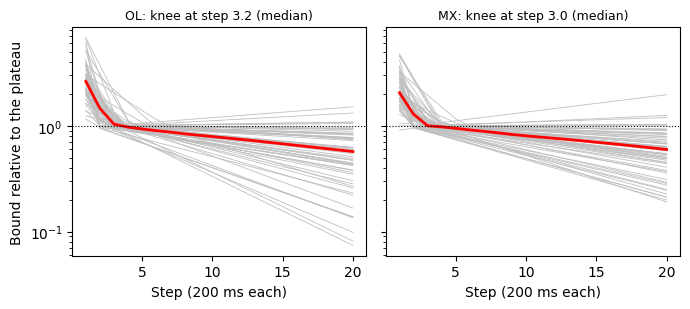

In [5]:
steps_ax = np.arange(1, 21)
conds = [(task, c) for task, d in tables.items() for c in sorted(d.condition.unique())]
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2), sharey=True)
for ax, task in zip(axes, DATASETS):
    s = by_subj.loc[task]
    curves = np.exp(get_log_h(s, steps_ax))
    ax.plot(steps_ax, curves.T, color='0.75', lw=0.6)
    ax.plot(steps_ax, np.median(curves, axis=0), 'r-', lw=2)
    ax.axhline(1, color='k', ls=':', lw=0.8)
    ax.set_title(f'{task}: knee at step {s.knee.median():.1f} (median)', fontsize=9)
    ax.set_xlabel('Step (200 ms each)')
axes[0].set_ylabel('Bound relative to the plateau')
axes[0].set_yscale('log')
plt.tight_layout()
plt.show()


### Model comparison across variants

Total negative log-likelihood and AIC (summed over subjects) per dataset. Lower
is better; AIC penalizes each free parameter by 2. AIC is a rough guide here
(the variants differ in flexibility in ways AIC handles imperfectly); held-out
likelihood is the planned check.

All variants use the current anticipation definition (RT = 1 only) and, except
`knots`, `flat_guess_tc` and `both_tc`, the knee form.

In [6]:
comp = []
for v, f in fits_all.items():
    s = f.groupby(['task', 'subject_index']).first()
    for task, g in s.groupby(level=0):
        comp.append({'variant': v, 'task': task, 'subjects': len(g), 'NLL': g.nll.sum(),
                     'AIC': (2 * g.nll + 2 * g.n_params).sum(), 'params / subject': g.n_params.median()})
comp = pd.DataFrame(comp)
comp['ΔAIC vs main'] = comp.AIC - comp.task.map(comp[comp.variant == 'main'].set_index('task').AIC)
comp.sort_values(['task', 'AIC']).round(1)

,variant,task,subjects,NLL,AIC,params / subject,ΔAIC vs main
0,main,MX,60,27013.1,56426.3,20.0,0.0
4,knee_flat,MX,60,27160.4,56600.8,19.0,174.5
18,ndt123,MX,60,27099.8,56719.7,21.0,293.4
6,tc_by_snr,MX,60,26980.2,56720.4,23.0,294.1
2,knots,MX,60,27326.8,56933.7,19.0,507.4
8,per_block_tc,MX,60,26953.8,57027.5,26.0,601.3
14,both_tc,MX,60,27302.3,57124.7,21.0,698.4
20,no_noise,MX,60,27430.0,57139.9,19.0,713.6
16,shared_rates,MX,60,27869.2,57418.3,14.0,992.0
10,flat,MX,60,28175.5,58390.9,17.0,1964.6


### Does the bound's time course differ by SNR?

An open question is whether people change the bound's dynamics, not only its
level, with SNR. The `tc_by_snr` variant is the main model with one time-course
shape per SNR instead of one per subject (column `snr_level`). In OL the SNRs are
in separate blocks (1–3 low, 4–6 high); in MX they are mixed within each block,
where a different shape would have to be set *after* the SNR becomes apparent
during the trial. Everything else (per-block plateau, CV and rates; shared noise
and NDT) is as in the main model, so the comparison costs 3 parameters per subject.


**Null check** (`scripts/run_stopping_tc_snr_null.py`): each subject's trials
simulated once from their main fit (one shape shared across SNRs), then fit with
both models. Shape differences and AIC gains in the null come from estimation
alone (high-SNR trials rarely reach late steps, so the penalty pulls the late
slope toward 0 there).

,total,median,by_snr_better,shared_better,subjects
task,,,,,
MX,294.1,5.2,2,46,60
OL,75.8,3.5,16,38,60


,task,quantity,low SNR median,high SNR median,median hi − lo,Wilcoxon p
0,MX,h(1) = exp(log_h_start),1.868,1.912,0.028,0.802
1,MX,knee (step),3.024,3.000,0.157,0.575
2,MX,late change per 10 steps,-0.262,-0.120,0.159,0.000
3,OL,h(1) = exp(log_h_start),2.301,2.189,-0.032,0.310
4,OL,knee (step),3.537,2.373,-0.927,0.001
5,OL,late change per 10 steps,-0.224,-0.089,0.079,0.000


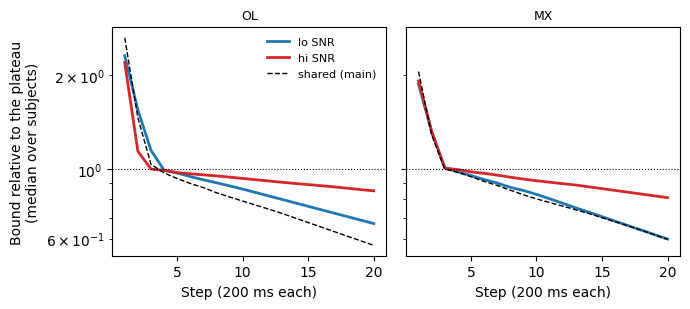

In [7]:
tc_snr = fits_all['tc_by_snr']
tc_shapes = tc_snr.groupby(['task', 'subject_index', 'time_course_group'])[list(KNEE_PARAMS)].first()

# Per-subject AIC: one shape per SNR vs. one shared shape.
aic = lambda f: (lambda s: 2 * s.nll + 2 * s.n_params)(f.groupby(['task', 'subject_index']).first())  # noqa: E731
d_aic = (aic(tc_snr) - aic(fits)).rename('ΔAIC (by SNR − shared)')
display(d_aic.groupby('task').agg(total='sum', median='median',
                                  by_snr_better=lambda v: int((v < -2).sum()),
                                  shared_better=lambda v: int((v > 2).sum()),
                                  subjects='size').round(1))

# Paired lo vs. hi shape parameters (Wilcoxon signed-rank across subjects).
import scipy.stats
rows = []
for task, g in tc_shapes.groupby(level='task'):
    w = g.droplevel('task').unstack('time_course_group')
    derived = {'h(1) = exp(log_h_start)': np.exp(w['log_h_start']), 'knee (step)': w['knee'],
               'late change per 10 steps': np.exp(10 * w['late_slope']) - 1}
    for name, v in derived.items():
        rows.append({'task': task, 'quantity': name, 'low SNR median': v['lo'].median(),
                     'high SNR median': v['hi'].median(), 'median hi − lo': (v['hi'] - v['lo']).median(),
                     'Wilcoxon p': scipy.stats.wilcoxon(v['hi'], v['lo']).pvalue})
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2), sharey=True)
for ax, task in zip(axes, DATASETS):
    for level, color in (('lo', 'tab:blue'), ('hi', 'tab:red')):
        s = tc_shapes.loc[(task, slice(None), level), :]
        ax.plot(steps_ax, np.median(np.exp(get_log_h(s, steps_ax)), axis=0), color=color, lw=2,
                label=f'{level} SNR')
    ax.plot(steps_ax, np.median(np.exp(get_log_h(by_subj.loc[task], steps_ax)), axis=0), 'k--', lw=1,
            label='shared (main)')
    ax.axhline(1, color='k', ls=':', lw=0.8)
    ax.set_title(task, fontsize=9)
    ax.set_xlabel('Step (200 ms each)')
axes[0].set_ylabel('Bound relative to the plateau\n(median over subjects)')
axes[0].set_yscale('log')
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


In [8]:
null = {'main': pd.read_pickle(PROCESSED / 'stopping_fits_null_snr_main.pkl'),
        'tc_by_snr': pd.read_pickle(PROCESSED / 'stopping_fits_null_snr_tc_by_snr.pkl')}
for name, f in null.items():
    bad = (~f.groupby(['task', 'subject_index']).success.first()).groupby('task').sum().to_dict()
    print(f'null fits, {name}: not converged by task {bad}')
d_aic_null = aic(null['tc_by_snr']) - aic(null['main'])

def _knee_diff(f):
    w = f.groupby(['task', 'subject_index', 'time_course_group']).knee.first().unstack()
    return w['hi'] - w['lo']

def _late_diff(f):
    w = f.groupby(['task', 'subject_index', 'time_course_group']).late_slope.first().unstack()
    return np.exp(10 * w['hi']) - np.exp(10 * w['lo'])

rows = []
for task in DATASETS:
    r, n = d_aic.loc[task], d_aic_null.loc[task]
    kr, kn = _knee_diff(tc_snr).loc[task], _knee_diff(null['tc_by_snr']).loc[task]
    lr, ln = _late_diff(tc_snr).loc[task], _late_diff(null['tc_by_snr']).loc[task]
    rows.append({'task': task, 'ΔAIC total, real': r.sum(), 'ΔAIC total, null': n.sum(),
                 'subjects by-SNR better (real / null)': f'{int((r < -2).sum())} / {int((n < -2).sum())}',
                 'ΔAIC real − null, median (Wilcoxon p)': f'{(r - n).median():.1f} ({scipy.stats.wilcoxon(r, n).pvalue:.2g})',
                 'knee hi − lo, real / null': f'{kr.median():.2f} / {kn.median():.2f}',
                 'knee: real vs null p': scipy.stats.wilcoxon(kr, kn).pvalue,
                 'late change hi − lo, real / null': f'{lr.median():.3f} / {ln.median():.3f}',
                 'late: real vs null p': scipy.stats.wilcoxon(lr, ln).pvalue})
pd.DataFrame(rows).set_index('task').T

null fits, main: not converged by task {'MX': 1, 'OL': 0}
null fits, tc_by_snr: not converged by task {'MX': 1, 'OL': 0}


task,OL,MX
"ΔAIC total, real",75.752713,294.104745
"ΔAIC total, null",365.022299,282.085506
subjects by-SNR better (real / null),16 / 0,2 / 1
"ΔAIC real − null, median (Wilcoxon p)",-2.0 (9.3e-05),0.7 (0.46)
"knee hi − lo, real / null",-0.93 / -0.36,0.16 / 0.00
knee: real vs null p,0.158106,0.723821
"late change hi − lo, real / null",0.079 / 0.070,0.159 / 0.107
late: real vs null p,0.250799,0.285777


**SNR and the bound's time course (2026-10-11).** One shape per subject is
preferred by AIC in both datasets (OL +76, MX +294). The apparent differences —
a shallower late decline at high SNR (both datasets) and an earlier knee at high
SNR (OL) — are mostly what estimation produces when the true shape is shared:
the null reproduces the late-slope difference almost exactly. **MX** (SNRs
mixed): real and null are indistinguishable, so no evidence that the dynamics
change with SNR. **OL** (SNRs blocked): the per-SNR model gains more on real
data than in the null (per-subject ΔAIC real − null: median −2.0, p = 0.0001;
16 vs. 0 subjects better by > 2), mainly via an earlier knee at high SNR (real
−0.9 steps vs. null −0.4; per subject not significant beyond the null,
p ≈ 0.16). So blocked-SNR subjects may shorten the early high-bound phase
slightly at high SNR; the large SNR effect is on the plateau (Figure 3E,
Figure 5), not the time course.

### Does the model describe the data? (posterior predictive checks)

Each subject is simulated from their own fitted parameters, five times over their
real trials (same condition, step statistics and trial count). Real (black) vs.
model (red), pooled over subjects.

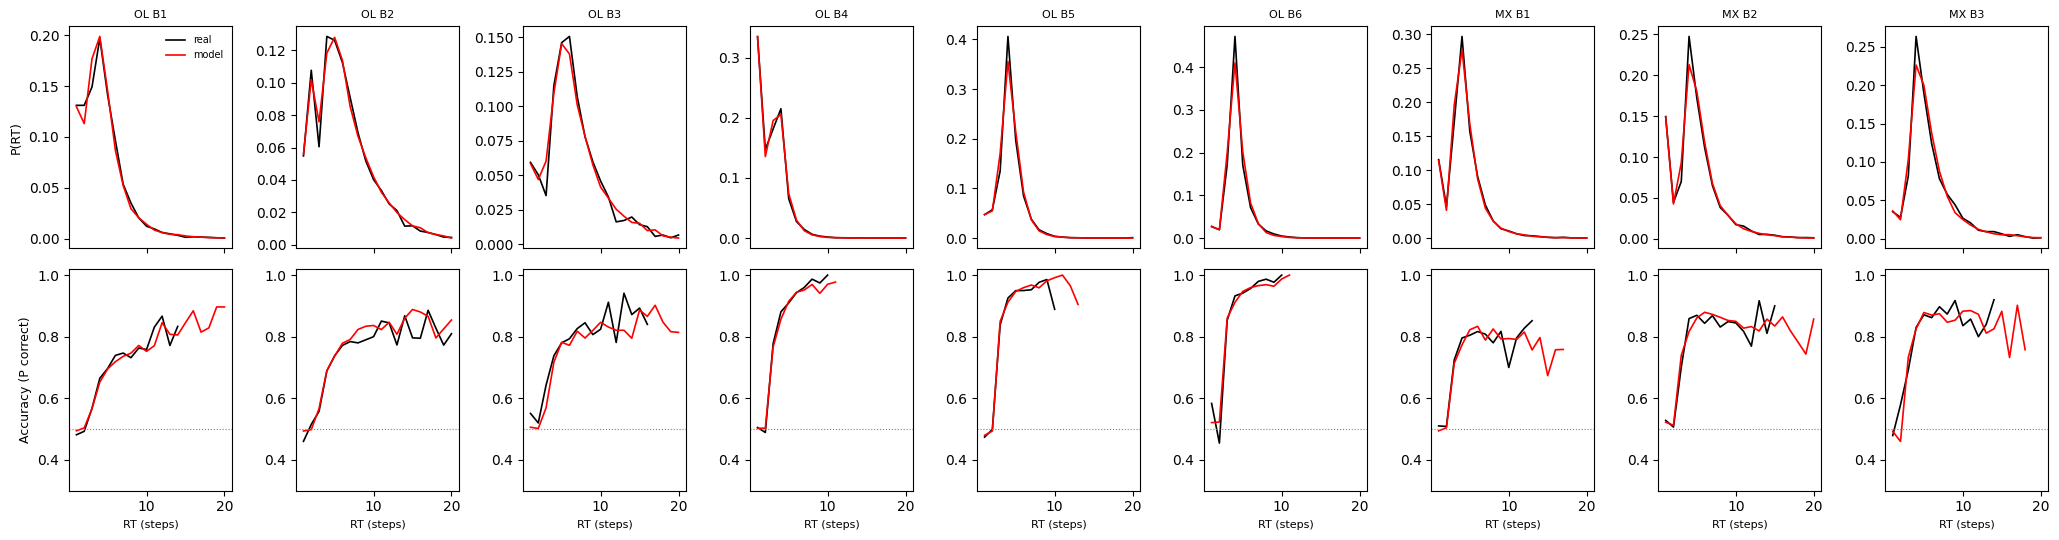

In [9]:
PPC_SEED = 11
PPC_REPS = 5
sims = {task: simulate_stopping_data_table(d, fits[fits.task == task], group_col='condition',
                                           num_reps=PPC_REPS, rng=np.random.default_rng(PPC_SEED))
        for task, d in tables.items()}

MAX_RT_SHOW = 20
rt_ax = np.arange(1, MAX_RT_SHOW + 1)
fig, axes = plt.subplots(2, len(conds), figsize=(2.3 * len(conds), 5.5), sharex=True)
for ci, (task, c) in enumerate(conds):
    real = tables[task][tables[task].condition == c]
    sim = sims[task][sims[task].condition == c]
    for t, col in ((real, 'k'), (sim, 'r')):
        axes[0, ci].plot(rt_ax, t.RT.value_counts(normalize=True).reindex(rt_ax, fill_value=0), '-', color=col, lw=1.2)
        acc = t.groupby('RT').correct.agg(['mean', 'size']).reindex(rt_ax)
        acc.loc[acc['size'] < 20, 'mean'] = np.nan
        axes[1, ci].plot(rt_ax, acc['mean'], '-', color=col, lw=1.2)
    axes[0, ci].set_title(f'{task} {c}', fontsize=8)
    axes[1, ci].axhline(0.5, color='gray', ls=':', lw=0.8)
    axes[1, ci].set_ylim(0.3, 1.02)
    axes[1, ci].set_xlabel('RT (steps)', fontsize=8)
axes[0, 0].set_ylabel('P(RT)', fontsize=9)
axes[1, 0].set_ylabel('Accuracy (P correct)', fontsize=9)
axes[0, 0].legend(['real', 'model'], fontsize=7, frameon=False)
plt.tight_layout()
plt.show()

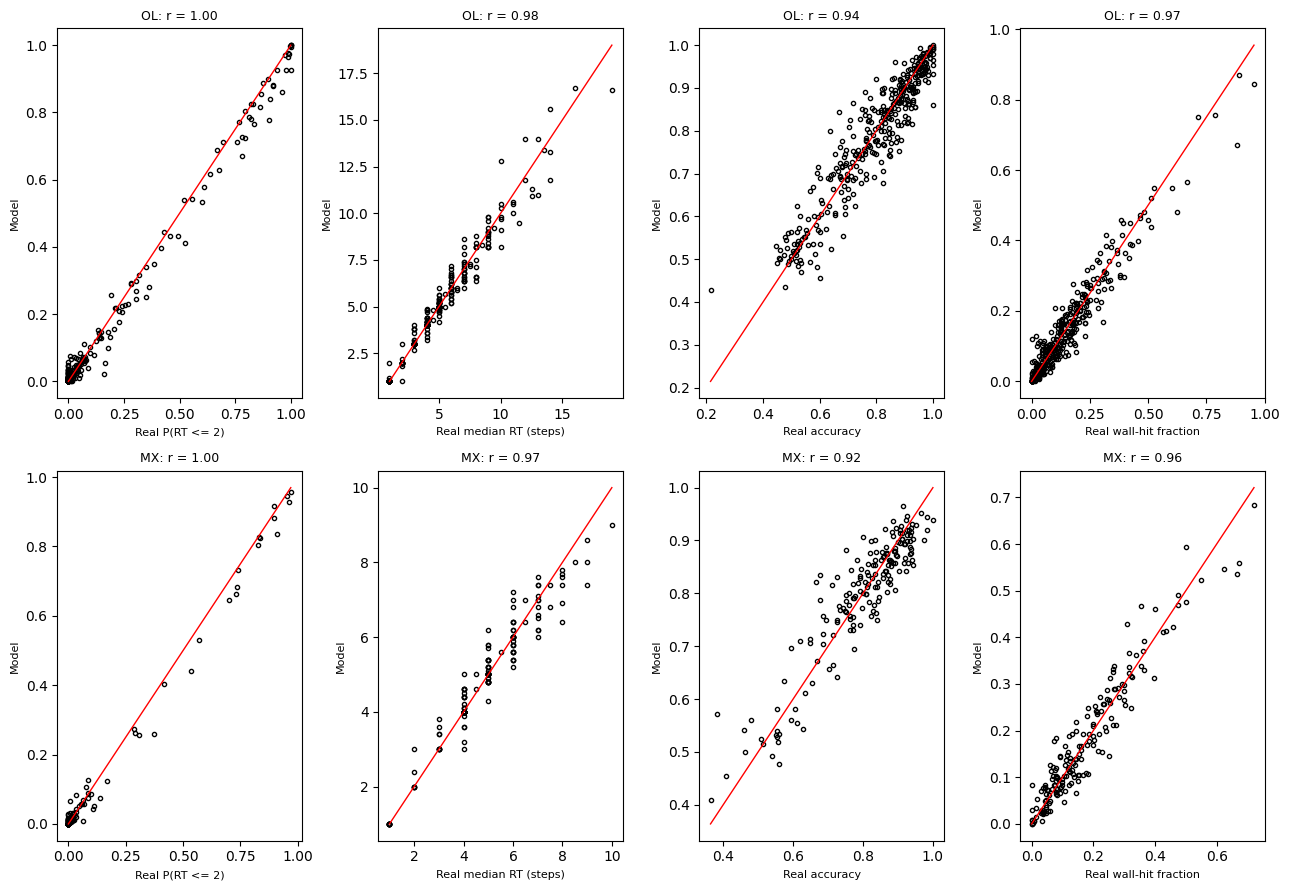

,task,statistic,r,mean real,mean model
0,OL,P(RT <= 2),0.996,0.129,0.125
1,OL,median RT (steps),0.982,5.056,5.048
2,OL,accuracy,0.941,0.791,0.789
3,OL,wall-hit fraction,0.965,0.147,0.145
4,MX,P(RT <= 2),0.997,0.087,0.083
5,MX,median RT (steps),0.969,4.822,4.823
6,MX,accuracy,0.921,0.797,0.797
7,MX,wall-hit fraction,0.957,0.174,0.177


In [10]:
def _subject_stats(t):
    g = t.groupby(['subject_index', 'condition'])
    return pd.DataFrame({'P(RT <= 2)': g.RT.apply(lambda r: np.mean(r <= 2)),
                         'median RT (steps)': g.RT.median(),
                         'accuracy': g.correct.mean(),
                         'wall-hit fraction': g.wall_hit.mean()})

STAT_NAMES = ['P(RT <= 2)', 'median RT (steps)', 'accuracy', 'wall-hit fraction']
fig, axes = plt.subplots(len(DATASETS), len(STAT_NAMES), figsize=(13, 9))
ppc_rows = []
for ti, task in enumerate(DATASETS):
    real = _subject_stats(tables[task])
    sim = sims[task].groupby('rep').apply(_subject_stats).groupby(level=[1, 2]).mean()
    both = real.join(sim, rsuffix=' model')
    for si, s in enumerate(STAT_NAMES):
        ax = axes[ti, si]
        ax.plot(both[s], both[f'{s} model'], 'o', mfc='none', color='k', ms=3)
        lims = [np.nanmin(both[[s, f'{s} model']].values), np.nanmax(both[[s, f'{s} model']].values)]
        ax.plot(lims, lims, 'r-', lw=1)
        rr = both[[s, f'{s} model']].corr().iloc[0, 1]
        ax.set_title(f'{task}: r = {rr:.2f}', fontsize=9)
        ax.set_xlabel(f'Real {s}', fontsize=8)
        ax.set_ylabel('Model', fontsize=8)
        ppc_rows.append({'task': task, 'statistic': s, 'r': rr,
                         'mean real': np.nanmean(both[s]), 'mean model': np.nanmean(both[f'{s} model'])})
plt.tight_layout()
plt.show()
pd.DataFrame(ppc_rows).round(3)

### Figure03S03's statistics: incongruence and premature crossings

The same definitions as Figure03S03 (`pigeon.data.get_crossing_diagnostics`),
computed on real data and on the model's simulated data after running both
through the real-data bound pipeline (`get_bounds` per subject; trials passing
`get_good_trial_array`: DT ≥ 2, trial_number ≥ 10, not a wall hit). Binned by
the inferred |bound| (0.1 wide). Per-subject bin means (≥ 5 trials), then mean ± SEM across
subjects (≥ 3 subjects). Figure03S03's fixed-bound scenarios could not reproduce
the incongruence floor at large bounds, or premature crossings with plausible NDTs.

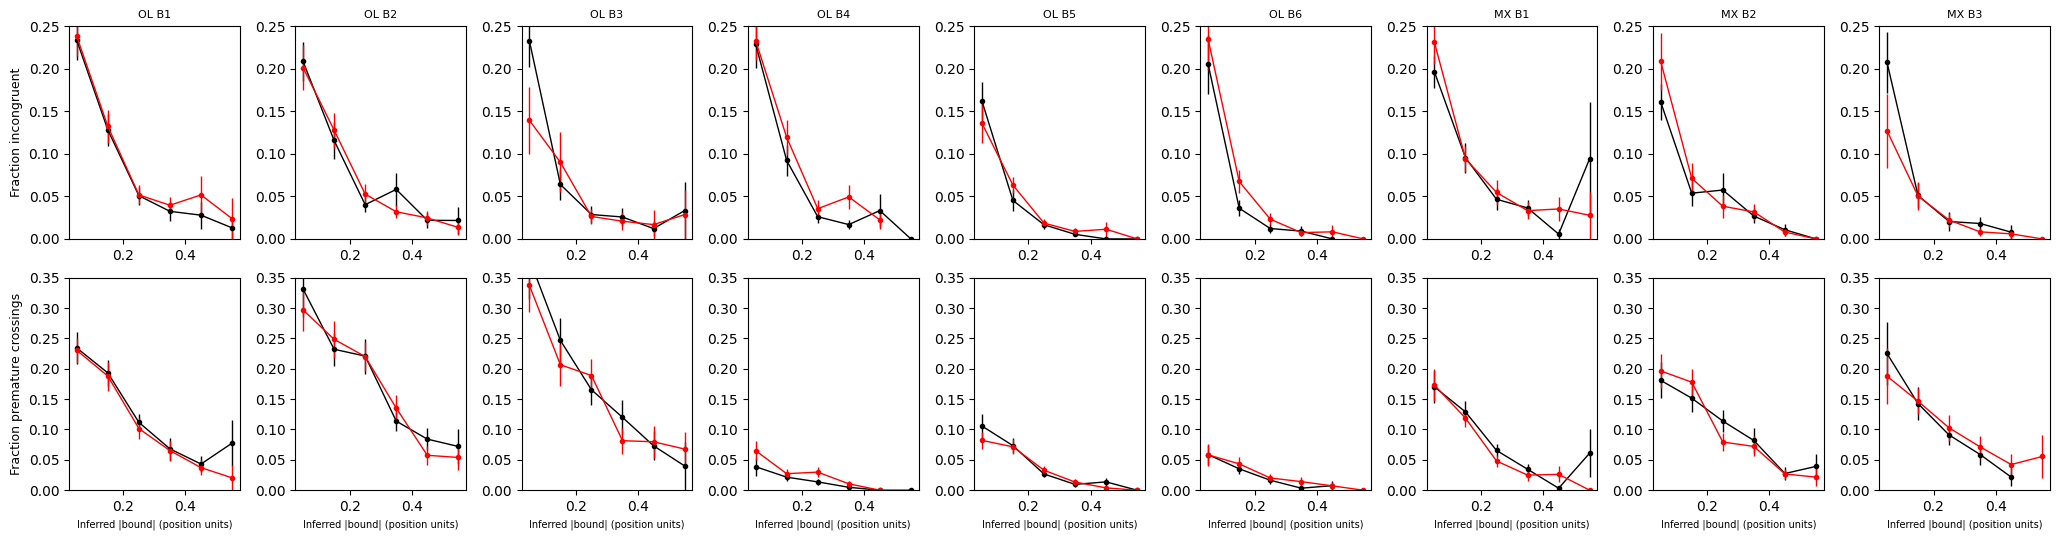

In [11]:
BIN_WIDTH = {'OL': 0.1, 'MX': 0.1}

def _diagnostics(t):
    t = t[get_good_trial_array(t, min_dt=2, min_trial_number=10)].copy()
    t[['incongruent', 'premature_crossing']] = get_crossing_diagnostics(t).values
    return t

def _binned(t, col, width, min_trials=5, min_subj=3):
    t = t.assign(_bin=np.floor(t.abs_bound / width))
    per_subj = t.groupby(['subject_index', '_bin'])[col].agg(['mean', 'size'])
    per_subj = per_subj[per_subj['size'] >= min_trials]['mean']
    g = per_subj.groupby(level='_bin').agg(['mean', 'sem', 'size'])
    g = g[g['size'] >= min_subj]
    return (g.index.to_numpy() + 0.5) * width, g['mean'].to_numpy(), g['sem'].to_numpy()

diag_real = {task: _diagnostics(d) for task, d in tables.items()}
diag_sim = {task: _diagnostics(infer_bounds_like_data(s[s.rep == 0]).assign(trial_number=99))
            for task, s in sims.items()}

fig, axes = plt.subplots(2, len(conds), figsize=(2.3 * len(conds), 5.5))
for ci, (task, c) in enumerate(conds):
    for ri, col in enumerate(('incongruent', 'premature_crossing')):
        ax = axes[ri, ci]
        for t, color in ((diag_real[task], 'k'), (diag_sim[task], 'r')):
            x, y, e = _binned(t[t.condition == c], col, BIN_WIDTH[task])
            ax.errorbar(x, y, yerr=e, fmt='o-', color=color, ms=3, lw=1, capsize=0)
        ax.set_ylim(0, 0.35 if ri else 0.25)
        if ri == 0:
            ax.set_title(f'{task} {c}', fontsize=8)
        else:
            ax.set_xlabel('Inferred |bound| (position units)', fontsize=7)
axes[0, 0].set_ylabel('Fraction incongruent', fontsize=9)
axes[1, 0].set_ylabel('Fraction premature crossings', fontsize=9)
plt.tight_layout()
plt.show()

### How many guesses survive the standard DT ≥ 2 filter?

In the simulated data each commit's source is known (bound crossing, guess or
anticipation). After the real-data bound pipeline and the paper's filter
(`get_good_trial_array`), what fraction of the surviving trials are guesses or
anticipations?

In [12]:
guess_rows = []
for task, s in sims.items():
    t = infer_bounds_like_data(s[s.rep == 0]).assign(trial_number=99)
    l_pass = get_good_trial_array(t, min_dt=2, min_trial_number=10)
    for c, tc in t.groupby('condition'):
        lp = l_pass.loc[tc.index]
        nonbound = tc.commit_type.isin(['guess', 'anticipation'])
        guess_rows.append({'task': task, 'condition': c,
                           'guess + anticipation, all trials': nonbound.mean(),
                           'guess + anticipation, passing filter': nonbound[lp].mean(),
                           'lapse, passing filter': tc.lapse[lp].mean(),
                           'fraction of trials passing': lp.mean()})
pd.DataFrame(guess_rows).round(3)

,task,condition,"guess + anticipation, all trials","guess + anticipation, passing filter","lapse, passing filter",fraction of trials passing
0,OL,B1,0.433,0.118,0.114,0.474
1,OL,B2,0.264,0.092,0.098,0.626
2,OL,B3,0.186,0.058,0.055,0.694
3,OL,B4,0.542,0.075,0.055,0.207
4,OL,B5,0.127,0.010,0.022,0.475
5,OL,B6,0.065,0.009,0.022,0.499
6,MX,B1,0.230,0.049,0.072,0.492
7,MX,B2,0.239,0.039,0.058,0.515
8,MX,B3,0.111,0.032,0.046,0.594


### Fitted bounds vs. the paper's median |bound|

How well do the fitted bounds match the per-subject bound summaries used so far,
and is either version of those summaries (raw or bias-corrected) biased relative
to the model? `pigeon.stopping.get_fit_vs_median_bounds` computes, per subject
and block:

- **median |bound|**: over the paper's standard trial set (`get_good_trial_array`:
  DT ≥ 2, trial_number ≥ 10, no wall hit, RT cutoff), raw and after
  `apply_bias_corrections` (`boundBiasCorrection.mat`);
- **effective fitted bound**: the model's mean bound at each trial's commit step
  (`RT − NDT − 1`, averaged over the fitted NDT), averaged over the same trials,
  so it weights the time course by when that subject responded.

The same is done on data simulated from the fits (three sessions per subject),
where the true bound is known. That gives the agreement to expect if the model
were exactly right, and shows whether the median method is biased under the
model.

In [13]:
from pigeon.data import get_data_table
from pigeon.path_defaults import BIAS_CORRECTION_FILE
from pigeon.stopping import get_fit_vs_median_bounds

FVM_SEED = 20261010
FVM_REPS = 3
fvm_real, fvm_sim = {}, {}
for task, blocks in DATASETS.items():
    raw = get_data_table(task_type=task, combine_snr=False, correct_bias=None)
    raw = raw[raw.block_index.isin(blocks)].copy()
    raw['condition'] = [f'B{b:.0f}' for b in raw.block_index]
    f_task = fits[fits.task == task]
    fvm_real[task] = get_fit_vs_median_bounds(raw, f_task, BIAS_CORRECTION_FILE)

    # Simulated sessions: each rep is its own subject-session, fit by the true parameters.
    sim = simulate_stopping_data_table(tables[task], f_task, group_col='condition', num_reps=FVM_REPS,
                                       rng=np.random.default_rng(FVM_SEED))
    sim = infer_bounds_like_data(sim).assign(trial_number=99)
    sim['subject_index'] = sim.subject_index * 10 + sim.rep
    f_rep = pd.concat([f_task.assign(subject_index=f_task.subject_index * 10 + r) for r in range(FVM_REPS)])
    fvm_sim[task] = get_fit_vs_median_bounds(sim, f_rep, BIAS_CORRECTION_FILE)

In [14]:
import scipy.stats

FVM_BOOT = 2000

def _rho_ci(x, y, rng):
    """Spearman r with a 95% bootstrap CI (resampling subjects)."""
    idx = rng.integers(0, len(x), (FVM_BOOT, len(x)))
    boot = [scipy.stats.spearmanr(x[i], y[i])[0] for i in idx]
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    return f'{scipy.stats.spearmanr(x, y)[0]:.2f} [{lo:.2f}, {hi:.2f}]'

rng_boot = np.random.default_rng(FVM_SEED)
fvm_rows = []
for task in DATASETS:
    for source, tab in (('real', fvm_real[task]), ('simulated', fvm_sim[task])):
        for c, g in tab.dropna().groupby('group'):
            row = {'task': task, 'block': c, 'data': source, 'n subjects': len(g)}
            for med in ('median_raw', 'median_corrected'):
                row[f'r: fit vs {med}'] = _rho_ci(g.effective_bound.to_numpy(), g[med].to_numpy(), rng_boot)
            for med in ('median_raw', 'median_corrected'):
                row[f'{med} / fit'] = np.median(g[med] / g.effective_bound)
            row['r: bound_scale vs median_corrected'] = _rho_ci(g.bound_scale.to_numpy(),
                                                                g.median_corrected.to_numpy(), rng_boot)
            fvm_rows.append(row)
pd.DataFrame(fvm_rows).set_index(['task', 'block', 'data']).sort_index(level=[0, 2, 1]).round(2)

n subjects r: fit vs median_raw  \
task block data                                         
MX   B1    real               60    0.66 [0.46, 0.80]   
     B2    real               59    0.62 [0.39, 0.78]   
     B3    real               59    0.59 [0.30, 0.81]   
     B1    simulated         180    0.66 [0.52, 0.77]   
     B2    simulated         180    0.57 [0.43, 0.71]   
     B3    simulated         168    0.67 [0.55, 0.77]   
OL   B1    real               59    0.62 [0.42, 0.77]   
     B2    real               60    0.53 [0.23, 0.77]   
     B3    real               55    0.79 [0.66, 0.86]   
     B4    real               56    0.43 [0.19, 0.64]   
     B5    real               58    0.55 [0.32, 0.74]   
     B6    real               52    0.65 [0.40, 0.81]   
     B1    simulated         179    0.55 [0.41, 0.67]   
     B2    simulated         179    0.53 [0.38, 0.66]   
     B3    simulated         167    0.64 [0.51, 0.76]   
     B4    simulated         169    0.34 [0.19, 0.48]   
     B5    simulated         180    0.49 [0.35, 0.62]   
     B6    simulated         164    0.62 [0.50, 0.73]   

                     r: fit vs median_corrected  median_raw / fit  \
task block data                                                     
MX   B1    real               0.64 [0.43, 0.78]              0.99   
     B2    real               0.61 [0.38, 0.78]              0.88   
     B3    real               0.58 [0.29, 0.81]              0.92   
     B1    simulated          0.65 [0.51, 0.76]              1.07   
     B2    simulated          0.59 [0.43, 0.72]              0.96   
     B3    simulated          0.67 [0.54, 0.78]              1.01   
OL   B1    real               0.65 [0.46, 0.81]              0.88   
     B2    real               0.53 [0.24, 0.76]              0.85   
     B3    real               0.79 [0.65, 0.87]              0.83   
     B4    real               0.42 [0.17, 0.62]              1.56   
     B5    real               0.54 [0.30, 0.73]              1.12   
     B6    real               0.64 [0.40, 0.81]              1.48   
     B1    simulated          0.55 [0.41, 0.67]              0.88   
     B2    simulated          0.53 [0.38, 0.66]              0.80   
     B3    simulated          0.64 [0.50, 0.76]              0.84   
     B4    simulated          0.34 [0.20, 0.48]              1.61   
     B5    simulated          0.48 [0.35, 0.61]              1.17   
     B6    simulated          0.61 [0.48, 0.72]              1.61   

                      median_corrected / fit  \
task block data                                
MX   B1    real                         0.92   
     B2    real                         0.87   
     B3    real                         0.93   
     B1    simulated                    1.02   
     B2    simulated                    0.96   
     B3    simulated                    0.98   
OL   B1    real                         0.88   
     B2    real                         0.85   
     B3    real                         0.85   
     B4    real                         1.36   
     B5    real                         1.04   
     B6    real                         1.32   
     B1    simulated                    0.89   
     B2    simulated                    0.82   
     B3    simulated                    0.85   
     B4    simulated                    1.38   
     B5    simulated                    1.07   
     B6    simulated                    1.37   

                     r: bound_scale vs median_corrected  
task block data                                          
MX   B1    real                       0.54 [0.33, 0.73]  
     B2    real                       0.52 [0.31, 0.69]  
     B3    real                       0.56 [0.27, 0.79]  
     B1    simulated                  0.60 [0.47, 0.72]  
     B2    simulated                  0.53 [0.38, 0.67]  
     B3    simulated                  0.67 [0.54, 0.78]  
OL   B1    real                       0.59 [0.37, 0.77]  
     B2    real  

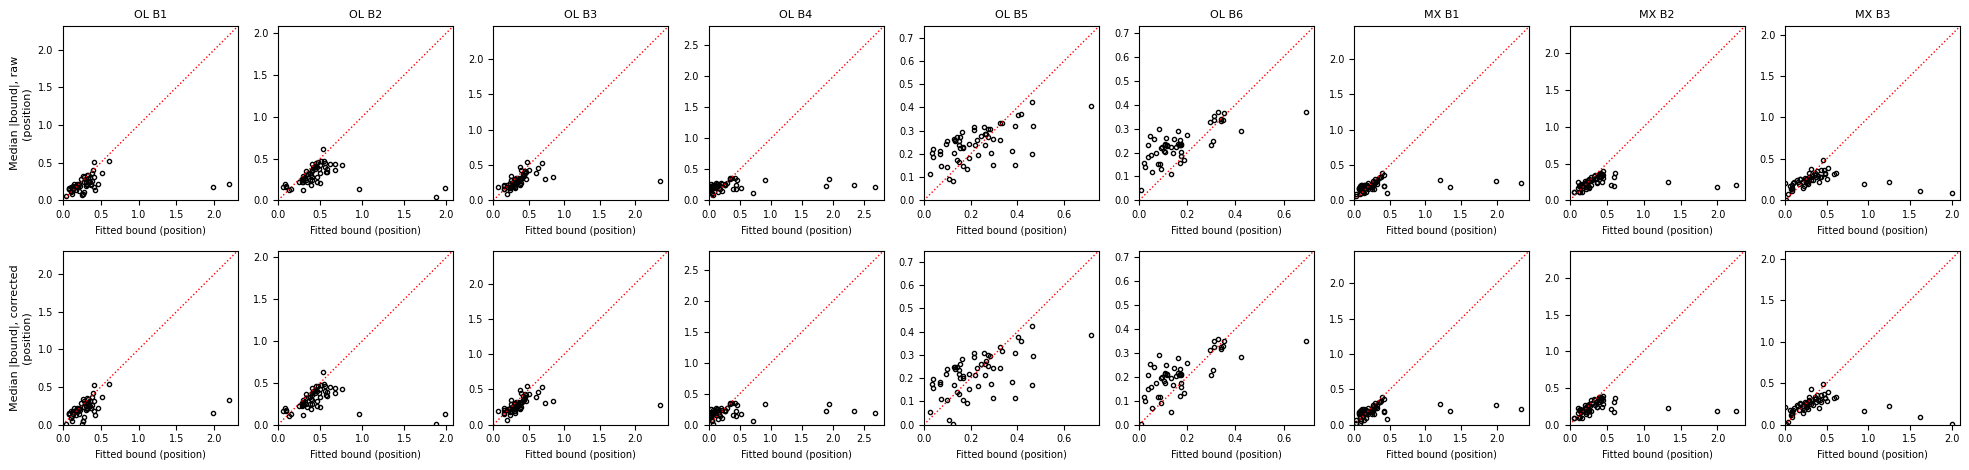

In [15]:
fig, axes = plt.subplots(2, len(conds), figsize=(2.2 * len(conds), 4.8))
for ci, (task, c) in enumerate(conds):
    g = fvm_real[task][fvm_real[task].group == c].dropna()
    for ri, med in enumerate(('median_raw', 'median_corrected')):
        ax = axes[ri, ci]
        ax.plot(g.effective_bound, g[med], 'o', mfc='none', color='k', ms=3)
        top = max(g.effective_bound.max(), g[med].max()) * 1.05
        ax.plot([0, top], [0, top], 'r:', lw=1)
        ax.set_xlim(0, top)
        ax.set_ylim(0, top)
        if ri == 0:
            ax.set_title(f'{task} {c}', fontsize=8)
        ax.set_xlabel('Fitted bound (position)', fontsize=7)
        ax.tick_params(labelsize=7)
axes[0, 0].set_ylabel('Median |bound|, raw\n(position)', fontsize=8)
axes[1, 0].set_ylabel('Median |bound|, corrected\n(position)', fontsize=8)
plt.tight_layout()
plt.show()

**Fitted vs. median bounds (2026-10-10).**

- **Ranking:** Spearman r between fitted and median bounds is moderate, about
  0.4–0.8 per block. On data simulated from the fits, where the model is true by
  construction, the median bound correlates with the true bound about as well
  (≈0.35–0.7). So the moderate agreement reflects how noisy the median bound is
  as a per-subject estimate (30–150 trials per block, mostly short DTs), not a
  disagreement between the fits and the medians.
- **Bias correction and correlation:** almost no effect; it rescales bounds
  within each DT × SNR bin nearly monotonically, so subjects' ranks barely move.
- **Level:** at low SNR (OL B1–B3) the median bound is ~13–15% below the fitted
  bound, raw or corrected. At high SNR (OL B4, B6) it is ~50% above raw and ~25%
  above after correction. MX is close to unbiased (0.9–1.0). The simulations
  reproduce these ratios closely (high-SNR OL corrected: 1.3–1.4; MX 1.0–1.1), so this is a bias of the median method
  under the model (the current correction ignores guesses and the early bound
  collapse), not a disagreement in the data. It implies that median-based
  high- vs. low-SNR bound comparisons in OL are exaggerated.
- **Do the fits need their own correction?** Not expected: overshoot, NDT,
  guesses and wall hits are in the likelihood, and recovery gives r = 0.94–0.99
  for `bound_scale`. The parametric bootstrap (`scripts/run_stopping_bootstrap.py`)
  checks fitted-vs-true bias at each subject's own parameters.

### Interpretation (2026-10-11, model version 3: knee time course)

- **Time-course form:** the knee form beats the knots form (ΔAIC −1,259 OL,
  −507 MX, with one more parameter per subject). Median shape: the bound starts
  2.6× (OL) / 2.05× (MX) above the plateau at step 1, reaches the plateau at a
  knee around step 3, then declines ~27% per 10 steps; a flat bound after the
  knee is worse (+530 OL, +174 MX).
- **Model comparison (knee form, refit 2026-10-11):** per-block time courses
  +1,154 OL / +601 MX (main better for 57 / 56 of 60 subjects); NDT 1–3
  +317 / +293 (P(NDT = 3) ≈ 0.5%, plateaus unchanged within 1%); no sensory
  noise +1,345 / +714; shared guess, lapse and anticipation rates +13,613 OL /
  +992 MX (in MX, 35 subjects slightly prefer shared rates; the total still
  favors per block); constant bound +4,629 / +1,965; a constant bound with a
  guess-rate time course +3,803 / +1,989 (the collapse is not replaceable by
  early guessing).
- **SNR:** see the null check above — no SNR-specific dynamics in MX, a weak
  earlier knee at high SNR in OL.
- **Fits at the plateau limits:** 12 OL and 8 MX subject-blocks have
  `bound_scale` at a fit limit (2.0: responding essentially at random, guess
  rate ≥ 0.5 per step, often lapse = 1; 0.002: committing on any movement).
  Their plateau is not a bound estimate; Figure 3E marks them separately.

### Interpretation (2026-10-10, round 3: anticipations at RT = 1 only)

- **Anticipation definition:** making anticipations first-frame presses only
  (and allowing guesses at step 0) improves the total NLL by 2,244 (OL) and 752
  (MX) with the same number of parameters, and removes the RT = 1 vs. 2 misfit:
  simulated RT = 1 and 2 fractions now match the data in every block (e.g. OL B4
  0.336 / 0.134 simulated vs. 0.335 / 0.147 real; previously 0.503 / 0.078).
  Remaining misfit: the model puts slightly too many responses at RT = 3 and too
  few at RT = 4 in OL B5/B6 and MX.
- **Fit quality:** per-subject P(RT ≤ 2), median RT, accuracy and wall-hit rate
  are reproduced (r = 0.92–1.0).
- **Bound time course:** the bound is ~2.4× (OL) / ~1.8× (MX) higher at step 1
  than at step 6, then ~11% lower by step 16.
- **Guesses, anticipations, lapses:** concentrated in OL B1, B4 and MX B1. After
  the paper's filter (DT ≥ 2, no wall hits, trial_number ≥ 10), simulated trials
  are 1–12% guesses or anticipations and 2–11% lapses, depending on block (round
  2: 9–23% and 2–15%).
- **Noise vs. guesses:** with the new definition, sensory noise roughly doubled
  (OL 0.04 → 0.09, MX 0.05 → 0.08) while guess rates fell to near zero in most
  blocks; bound levels barely moved. The noise / bound CV / guess split is not
  well pinned down; the parametric bootstrap tests it at each subject's own
  parameters.

### Interpretation (2026-10-10, round 2)

- **Model comparison (AIC, summed over subjects):** the main model (bound scale,
  CV and the three rates per block; time course, noise and NDT shared) is best in
  both datasets. Next best: NDT 1–3 (+148 OL, +304 MX), per-block time courses
  (+874, +378), no sensory noise (+964, +238), constant bound (+3,097, +1,322),
  shared rates (+12,068, +987).
- **Fit quality:** per-subject statistics and Figure03S03's incongruence and
  premature-crossing curves were matched in all OL and MX blocks with NDT ≤ 2;
  RT = 1 was over- and RT = 2 under-predicted (fixed in round 3).
- **Guesses:** 9–23% guesses or anticipations and 2–15% lapses after the paper's
  filter; sensory noise ~0.04, bound CV ~0.4.